<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week2/lesson6/Lesson6_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 6 — Eigenstructure and Stability: What Happens When a Matrix Is Applied Again and Again

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 2 — Linear Algebra II\
**Lesson:** Lesson 6\
**Notebook type:** Teaching notebook

> *"Most directions get twisted by a matrix. A few are only stretched. Those few directions decide whether a recurrent network forgets, remembers, oscillates or explodes."*

---

### From one step to many

Lessons 4 and 5 applied a matrix once. In a **recurrent** network the output feeds back as the next input. Activity now is a matrix times activity a moment ago:

$$\mathbf{x}_{t+1} = \mathbf{W}\mathbf{x}_t \quad\Longrightarrow\quad \mathbf{x}_t = \mathbf{W}^t\mathbf{x}_0 .$$

What does $\mathbf{W}^t$ do as $t$ grows? Does activity die away, settle, oscillate, or blow up, and how fast? Multiplying $\mathbf{W}$ by itself a hundred times will not tell you why. The answer lies in a few special directions, the **eigenvectors**, and their stretch factors, the **eigenvalues**. This lesson finds them, reads stability and timescales from them, and then fits a dynamics matrix to real motor-cortex activity and asks what its eigenvalues say, and what they do not.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-5.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-5.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def rotation(deg):
    t = np.radians(deg)
    return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

def iterate(W, x0, n_steps):
    # Return the trajectory x_0, x_1, ..., x_n of x_{t+1} = W x_t as an array of shape (n_steps + 1, len(x0)).
    xs = [np.asarray(x0, float)]
    for _ in range(n_steps):
        xs.append(W @ xs[-1])
    return np.array(xs)

unit_circle = np.exp(1j * np.linspace(0, 2 * np.pi, 300))
print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: three recurrent networks, three fates**

Two neurons excite and inhibit each other. Their rates (relative to baseline) at time step $t$ form $\mathbf{x}_t$, and each step $\mathbf{x}_{t+1} = \mathbf{W}\mathbf{x}_t$. Here are three weight matrices, all started from the same small perturbation $\mathbf{x}_0 = (1,\ 0.5)$.

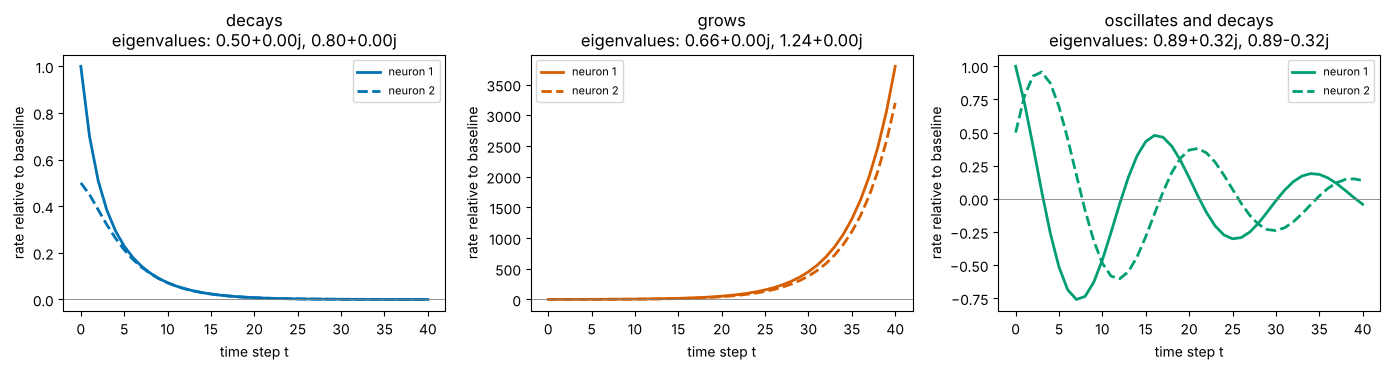

In [3]:
W_decay = np.array([[0.6, 0.2], [0.1, 0.7]])
W_grow = np.array([[0.9, 0.4], [0.2, 1.0]])
W_osc = 0.95 * rotation(20)
x0 = np.array([1.0, 0.5])
nets = {'decays': W_decay, 'grows': W_grow, 'oscillates and decays': W_osc}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, W), colour in zip(axes, nets.items(), PALETTE):
    traj = iterate(W, x0, 40)
    ax.plot(traj[:, 0], color=colour, lw=2, label='neuron 1')
    ax.plot(traj[:, 1], color=colour, lw=2, ls='--', label='neuron 2')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_xlabel('time step t'); ax.set_ylabel('rate relative to baseline')
    ax.set_title(f'{name}\neigenvalues: ' + ', '.join(f'{l:.2f}' for l in np.linalg.eigvals(W)))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The titles already hold the answer. All eigenvalues inside the unit circle: activity decays. One outside: it grows. A complex pair: it rotates, here while shrinking. By the end of this lesson you will be able to read these fates, and their **timescales**, directly from the eigenvalues, without simulating anything.

# **Part 1: Eigenvectors — Directions a Matrix Only Stretches**

Lesson 4 showed that a matrix generally **turns** vectors as well as stretching them. An **eigenvector** of a square matrix $\mathbf{A}$ is a nonzero vector that is not turned, only scaled:

$$\mathbf{A}\mathbf{v} = \lambda\mathbf{v}.$$

The number $\lambda$ is the **eigenvalue**: the factor by which that direction is stretched ($|\lambda| > 1$), shrunk ($|\lambda| < 1$) or flipped ($\lambda < 0$). Any nonzero multiple of an eigenvector is also an eigenvector, so what matters is the **direction**; NumPy returns eigenvectors scaled to length 1.

The figure applies $\mathbf{A} = \begin{pmatrix}2 & 1\\ 1 & 2\end{pmatrix}$ to unit vectors pointing in many directions. Most outputs point in a different direction from their inputs. Along the diagonals, they do not.

eigenvalues : [3. 1.]
eigenvectors (columns):
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
A v = [2.1213 2.1213]   lambda v = [2.1213 2.1213]
A v = [-0.7071  0.7071]   lambda v = [-0.7071  0.7071]


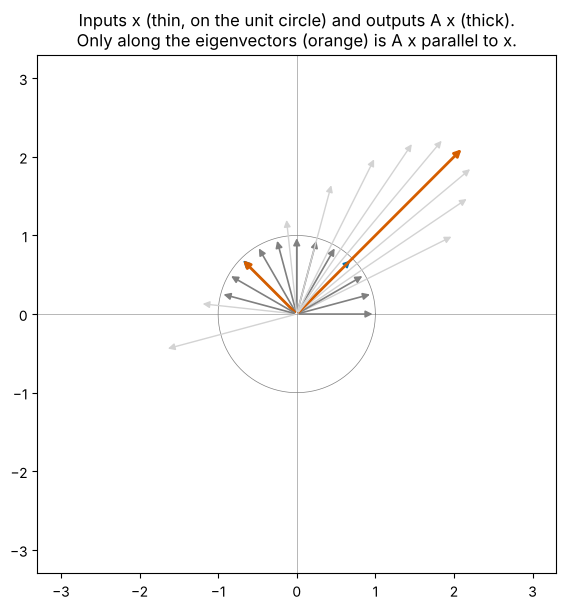

In [4]:
A1 = np.array([[2.0, 1.0], [1.0, 2.0]])
eigvals1, eigvecs1 = np.linalg.eig(A1)        # eigenvectors are the COLUMNS of eigvecs1
eigvals1, eigvecs1 = np.real_if_close(eigvals1), np.real_if_close(eigvecs1)   # drop zero imaginary parts for display
print("eigenvalues :", eigvals1)
print("eigenvectors (columns):\n", np.round(eigvecs1, 4))
for k in range(2):
    v = eigvecs1[:, k]
    print(f"A v = {np.round(A1 @ v, 4)}   lambda v = {np.round(eigvals1[k] * v, 4)}")

angles = np.radians(np.arange(0, 180, 15))
fig, ax = plt.subplots(figsize=(6.2, 6.2))
for a in angles:
    x = np.array([np.cos(a), np.sin(a)]); y = A1 @ x
    is_eig = np.isclose(abs(x[0] * y[1] - x[1] * y[0]), 0, atol=1e-9)   # zero 2-D cross product: parallel
    colour = PALETTE[1] if is_eig else 'lightgrey'
    ax.annotate('', xy=x, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=PALETTE[0] if is_eig else 'grey', lw=1.2))
    ax.annotate('', xy=y, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=colour, lw=2 if is_eig else 1))
ax.plot(np.cos(np.linspace(0, 2 * np.pi, 200)), np.sin(np.linspace(0, 2 * np.pi, 200)), color='grey', lw=0.5)
ax.set_xlim(-3.3, 3.3); ax.set_ylim(-3.3, 3.3); ax.set_aspect('equal')
ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
ax.set_title('Inputs x (thin, on the unit circle) and outputs A x (thick).\nOnly along the eigenvectors (orange) is A x parallel to x.')
plt.tight_layout()
plt.show()

#### Animation: rotate the input and watch for the moment the output lines up

In [5]:
# INTERACTIVE ANIMATION -- the input x sweeps round the circle; A x is drawn from the origin
sweep = np.arange(0, 181, 5)
def arrows_for(deg):
    x = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))]); y = A1 @ x
    ang = np.degrees(np.arccos(np.clip(x @ y / np.linalg.norm(y), -1, 1)))
    return x, y, ang
x_, y_, ang_ = arrows_for(0)
fig_eig = go.Figure([
    go.Scatter(x=np.cos(np.linspace(0, 2 * np.pi, 200)), y=np.sin(np.linspace(0, 2 * np.pi, 200)), mode='lines', line=dict(color='lightgrey'), hoverinfo='skip', name='unit circle'),
    go.Scatter(x=[0, x_[0]], y=[0, x_[1]], mode='lines+markers', line=dict(color=PALETTE[0], width=4), name='x'),
    go.Scatter(x=[0, y_[0]], y=[0, y_[1]], mode='lines+markers', line=dict(color=PALETTE[1], width=4), name='A x'),
])
fig_eig.frames = [go.Frame(name=str(k), traces=[1, 2], data=[go.Scatter(x=[0, arrows_for(d)[0][0]], y=[0, arrows_for(d)[0][1]]),
                                                             go.Scatter(x=[0, arrows_for(d)[1][0]], y=[0, arrows_for(d)[1][1]])],
                           layout=go.Layout(title=f'x at {d} deg: angle between x and A x = {arrows_for(d)[2]:.1f} deg' + ('   <- eigenvector!' if arrows_for(d)[2] < 0.5 else '')))
                  for k, d in enumerate(sweep)]
buttons, sliders = play_pause_and_slider([f'{d}' for d in sweep], prefix='input direction (deg) = ', duration=250)
fig_eig.update_layout(title=fig_eig.frames[0].layout.title.text, xaxis=dict(range=[-3.3, 3.3]), yaxis=dict(range=[-3.3, 3.3], scaleanchor='x', scaleratio=1),
                      template='plotly_white', width=640, height=640, updatemenus=buttons, sliders=sliders)
fig_eig.show(config=PLOTLY_CONFIG)

At 45° the output is the input stretched by 3: eigenvalue 3, eigenvector $(1, 1)/\sqrt2$. At 135° the output is the input itself: eigenvalue 1, eigenvector $(-1, 1)/\sqrt2$. Every other input is a mixture of these two directions, and the next parts show why that makes eigenvectors so useful.

# **Part 2: Finding Eigenvalues — the Characteristic Equation**

$\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$ can be rewritten as $(\mathbf{A} - \lambda\mathbf{I})\mathbf{v} = \mathbf{0}$. A nonzero $\mathbf{v}$ can solve this only if $\mathbf{A} - \lambda\mathbf{I}$ squashes some direction to zero, which (Lesson 4) happens exactly when its determinant is zero:

$$\det(\mathbf{A} - \lambda\mathbf{I}) = 0 .$$

For a $2\times2$ matrix $\begin{pmatrix}a & b\\ c & d\end{pmatrix}$ this is a quadratic, the **characteristic equation**:

$$\lambda^2 - (a + d)\,\lambda + (ad - bc) = 0, \qquad\text{that is,}\qquad \lambda^2 - \operatorname{tr}(\mathbf{A})\,\lambda + \det(\mathbf{A}) = 0,$$

where the **trace** $\operatorname{tr}(\mathbf{A}) = a + d$ is the sum of the diagonal. The quadratic formula gives the eigenvalues, and two useful checks follow: **the eigenvalues add up to the trace and multiply to the determinant.**

The **discriminant** $\Delta = \operatorname{tr}^2 - 4\det$ decides the type:
- $\Delta > 0$: two different **real** eigenvalues;
- $\Delta = 0$: one **repeated** real eigenvalue;
- $\Delta < 0$: a **complex** pair $\alpha \pm i\beta$, which signals rotation (Part 3).

In [6]:
def eig_2x2(A):
    # Eigenvalues of a 2x2 matrix from the characteristic equation (complex if the discriminant is negative).
    tr, det = np.trace(A), np.linalg.det(A)
    disc = tr**2 - 4 * det
    root = np.sqrt(complex(disc))
    return np.array([(tr + root) / 2, (tr - root) / 2]), disc

examples = {
    'symmetric [[2,1],[1,2]]': A1,
    'two neurons, decaying': W_decay,
    'scalar 2 I': 2 * np.eye(2),
    'shear [[1,1],[0,1]]': np.array([[1.0, 1.0], [0.0, 1.0]]),
    '0.95 x rotation 20 deg': W_osc,
}
print(f"{'matrix':<26}{'trace':>7}{'det':>7}{'disc':>8}   eigenvalues (formula)          np.linalg.eigvals")
for name, M in examples.items():
    lam, disc = eig_2x2(M)
    kind = 'complex' if disc < -1e-12 else ('repeated' if abs(disc) < 1e-12 else 'real')
    print(f"{name:<26}{np.trace(M):7.2f}{np.linalg.det(M):7.2f}{disc:8.2f}   {np.round(np.real_if_close(lam), 3)!s:<30} {np.round(np.real_if_close(np.linalg.eigvals(M)), 3)}   ({kind})")

matrix                      trace    det    disc   eigenvalues (formula)          np.linalg.eigvals
symmetric [[2,1],[1,2]]      4.00   3.00    4.00   [3. 1.]                        [3. 1.]   (real)
two neurons, decaying        1.30   0.40    0.09   [0.8 0.5]                      [0.5 0.8]   (real)
scalar 2 I                   4.00   4.00    0.00   [2. 2.]                        [2. 2.]   (repeated)
shear [[1,1],[0,1]]          2.00   1.00    0.00   [1. 1.]                        [1. 1.]   (repeated)
0.95 x rotation 20 deg       1.79   0.90   -0.42   [0.893+0.325j 0.893-0.325j]    [0.893+0.325j 0.893-0.325j]   (complex)


**Repeated eigenvalues come in two kinds.** $2\mathbf{I}$ has the eigenvalue 2 twice, and *every* vector is an eigenvector. The shear also has the eigenvalue 1 twice, but only one eigenvector direction, $(1, 0)$: it slides everything else sideways. Such a matrix is called **defective**, and it cannot be fully described by its eigenvectors (Part 4). Defective matrices are rare in data, because almost any perturbation splits the repeated eigenvalue, but they mark the boundary between behaviours.

For matrices larger than $2\times2$ the characteristic polynomial has degree $n$, and nobody solves it by hand. `np.linalg.eig` uses a much more stable iterative method. The idea, though, is the same: an $n\times n$ matrix has $n$ eigenvalues (counting repeats), some possibly complex.

# **Part 3: Complex Eigenvalues Mean Rotation**

A rotation by $\theta$ turns **every** direction, so it has no real eigenvector, and its characteristic equation has no real root. Its eigenvalues are the complex pair $\cos\theta \pm i\sin\theta = e^{\pm i\theta}$.

In general, a real matrix with complex eigenvalues $\lambda = r\,e^{\pm i\theta}$ acts, in a suitable plane, like **rotation by $\theta$ combined with scaling by $r = |\lambda|$**. Repeated application traces a **spiral**: inward if $r < 1$, outward if $r > 1$, a closed loop if $r = 1$. The modulus $|\lambda|$ controls growth or decay; the angle $\theta$ controls how fast it turns.

This is how a linear network oscillates: neuron 1 excites neuron 2, neuron 2 inhibits neuron 1, and activity chases itself round. Excitatory–inhibitory loops of this kind are a classic source of rhythms in the brain.

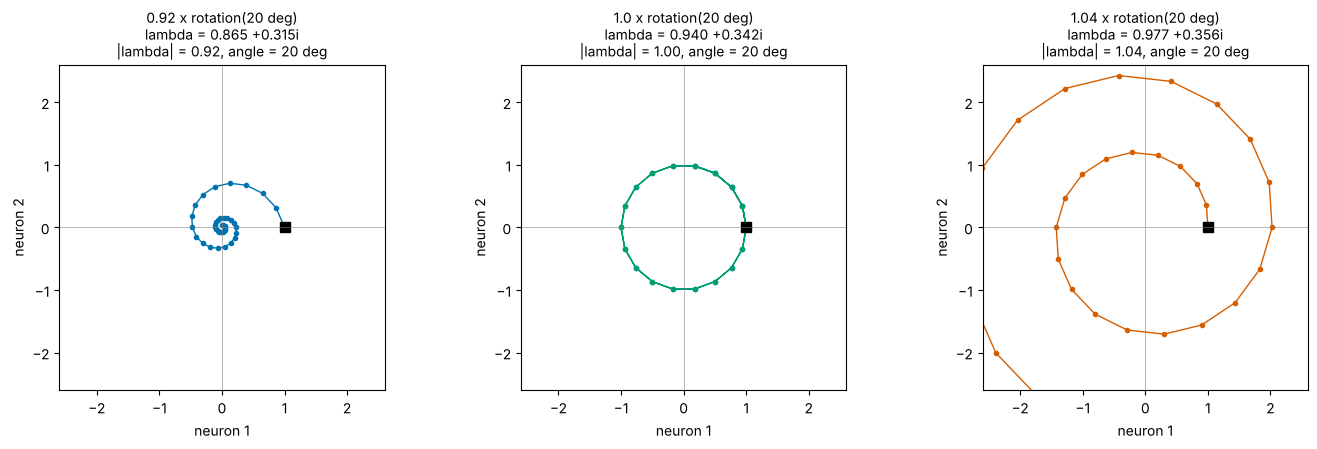

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (r, colour) in zip(axes, [(0.92, PALETTE[0]), (1.0, PALETTE[2]), (1.04, PALETTE[1])]):
    M = r * rotation(20)
    traj = iterate(M, [1.0, 0.0], 40)
    lam = np.linalg.eigvals(M)[0]
    ax.plot(traj[:, 0], traj[:, 1], '-o', ms=3, color=colour, lw=1)
    ax.plot(*traj[0], 'ks', ms=7)
    ax.set_aspect('equal'); ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6)
    ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
    ax.set_xlabel('neuron 1'); ax.set_ylabel('neuron 2')
    ax.set_title(f'{r} x rotation(20 deg)\nlambda = {lam.real:.3f} {lam.imag:+.3f}i\n|lambda| = {abs(lam):.2f}, angle = {np.degrees(np.angle(lam)):.0f} deg', fontsize=10)
plt.tight_layout()
plt.show()

# **Part 4: Diagonalisation and Mode Decomposition**

Suppose an $n\times n$ matrix has $n$ independent eigenvectors $\mathbf{v}_1, \dots, \mathbf{v}_n$ (true whenever the eigenvalues are all different). Put them as the columns of $\mathbf{V}$, and the eigenvalues on the diagonal of $\boldsymbol\Lambda$. Then $\mathbf{A}\mathbf{V} = \mathbf{V}\boldsymbol\Lambda$, so

$$\mathbf{A} = \mathbf{V}\boldsymbol\Lambda\mathbf{V}^{-1}, \qquad \mathbf{A}^t = \mathbf{V}\boldsymbol\Lambda^t\mathbf{V}^{-1}.$$

Raising a diagonal matrix to a power is trivial: raise each diagonal entry. This is **diagonalisation**: in the coordinates given by the eigenvectors, the matrix just scales each axis separately.

**Mode decomposition.** Write the starting state in the eigenvector basis, $\mathbf{x}_0 = c_1\mathbf{v}_1 + \cdots + c_n\mathbf{v}_n$ (the coefficients are $\mathbf{c} = \mathbf{V}^{-1}\mathbf{x}_0$). Each eigenvector is only scaled at each step, so

$$\mathbf{x}_t = c_1\lambda_1^t\,\mathbf{v}_1 + c_2\lambda_2^t\,\mathbf{v}_2 + \cdots + c_n\lambda_n^t\,\mathbf{v}_n .$$

The dynamics split into independent **modes**, each with its own fate. The mode with the largest $|\lambda|$, the **dominant mode**, outlasts the rest, so activity lines up with its eigenvector over time.

In [8]:
A4 = np.array([[0.8, 0.3], [0.1, 0.6]])
lam4, V4 = np.linalg.eig(A4)
lam4, V4 = np.real_if_close(lam4), np.real_if_close(V4)
order4 = np.argsort(-np.abs(lam4)); lam4, V4 = lam4[order4], V4[:, order4]
print("eigenvalues:", lam4)
print("A = V Lambda V^-1 ?", np.allclose(A4, V4 @ np.diag(lam4) @ np.linalg.inv(V4)))
print("A^20 via eigenvalues equals matrix_power?", np.allclose(V4 @ np.diag(lam4**20) @ np.linalg.inv(V4), np.linalg.matrix_power(A4, 20)))

x0_4 = np.array([-0.4, 1.0])
c4 = np.linalg.solve(V4, x0_4)                                   # coordinates of x0 in the eigenvector basis
print("x0 =", x0_4, " = ", f"{c4[0]:.3f} v1 + {c4[1]:.3f} v2")
t4 = np.arange(25)
mode1 = np.outer(c4[0] * lam4[0]**t4, V4[:, 0])                  # shape (25, 2): slow mode's contribution
mode2 = np.outer(c4[1] * lam4[1]**t4, V4[:, 1])                  # fast mode's contribution
traj4 = iterate(A4, x0_4, 24)
print("trajectory = sum of the two modes?", np.allclose(traj4, mode1 + mode2))

eigenvalues: [0.9 0.5]
A = V Lambda V^-1 ? True
A^20 via eigenvalues equals matrix_power? True
x0 = [-0.4  1. ]  =  0.474 v1 + 1.202 v2
trajectory = sum of the two modes? True


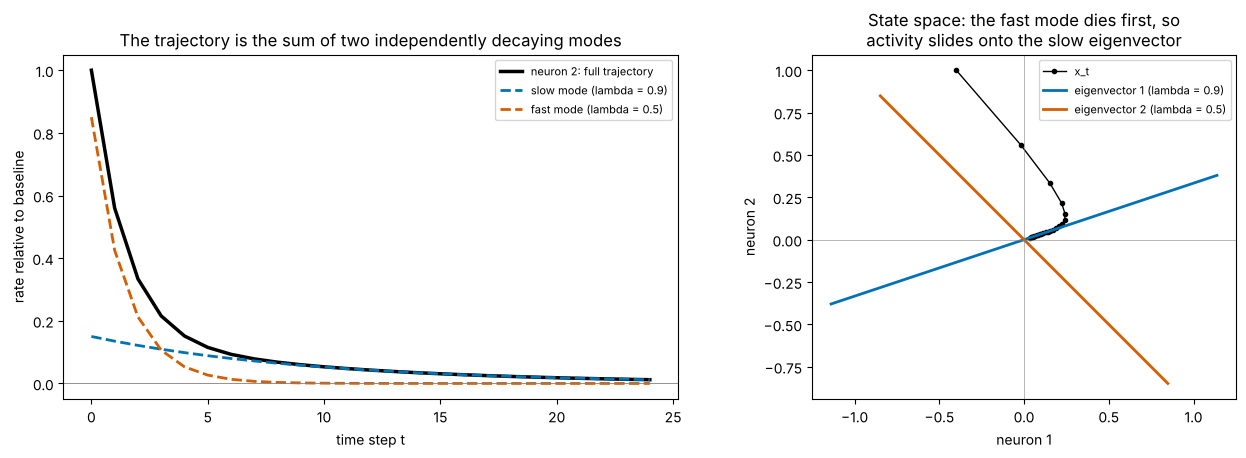

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
ax = axes[0]
ax.plot(t4, traj4[:, 1], 'k-', lw=2.5, label='neuron 2: full trajectory')
ax.plot(t4, mode1[:, 1], color=PALETTE[0], lw=2, ls='--', label=f'slow mode (lambda = {lam4[0]:.1f})')
ax.plot(t4, mode2[:, 1], color=PALETTE[1], lw=2, ls='--', label=f'fast mode (lambda = {lam4[1]:.1f})')
ax.axhline(0, color='grey', lw=0.6)
ax.set_xlabel('time step t'); ax.set_ylabel('rate relative to baseline'); ax.set_title('The trajectory is the sum of two independently decaying modes')
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(traj4[:, 0], traj4[:, 1], '-o', color='black', ms=3, lw=1, label='x_t')
for k, colour in zip(range(2), PALETTE):
    v = V4[:, k]
    ax.plot([-1.2 * v[0], 1.2 * v[0]], [-1.2 * v[1], 1.2 * v[1]], color=colour, lw=2, label=f'eigenvector {k + 1} (lambda = {lam4[k]:.1f})')
ax.set_aspect('equal'); ax.axhline(0, color='grey', lw=0.4); ax.axvline(0, color='grey', lw=0.4)
ax.set_xlabel('neuron 1'); ax.set_ylabel('neuron 2'); ax.set_title('State space: the fast mode dies first, so\nactivity slides onto the slow eigenvector')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Power iteration: finding the dominant mode by repetition

Because the dominant mode wins, simply applying $\mathbf{A}$ again and again to almost any starting vector, rescaling to length 1 each time, converges to the dominant eigenvector. This **power iteration** is how web-page ranking and many large-scale eigenvalue methods work. It converges at a rate set by $|\lambda_2/\lambda_1|$: fast when the dominant eigenvalue stands well clear of the rest.

In [10]:
def power_iteration(A, n_iter=50, seed=0):
    v = np.random.default_rng(seed).normal(size=A.shape[0])
    for _ in range(n_iter):
        v = A @ v
        v = v / np.linalg.norm(v)
    return v, v @ A @ v           # direction, and the Rayleigh quotient as the eigenvalue estimate

v_pow, lam_pow = power_iteration(A4)
print("power iteration:", np.round(v_pow * np.sign(v_pow[0]), 4), f" eigenvalue estimate {lam_pow:.4f}")
print("np.linalg.eig  :", np.round(V4[:, 0] * np.sign(V4[0, 0]), 4), f" eigenvalue {lam4[0]:.4f}")

power iteration: [0.9487 0.3162]  eigenvalue estimate 0.9000
np.linalg.eig  : [0.9487 0.3162]  eigenvalue 0.9000


### Symmetric matrices: the best-behaved case

If $\mathbf{A} = \mathbf{A}^{\mathsf T}$ (Lesson 3), then all its eigenvalues are **real**, and eigenvectors for different eigenvalues are **orthogonal** (the notes prove both). The eigenvectors then form an orthonormal basis, a rotated set of axes, and $\mathbf{A} = \mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^{\mathsf T}$ with $\mathbf{Q}^{-1} = \mathbf{Q}^{\mathsf T}$. Use `np.linalg.eigh` for symmetric matrices: it is faster and guarantees real, orthonormal output.

Covariance matrices are symmetric, which is why Lesson 7 (PCA) is entirely about this case.

In [11]:
S6 = RNG.normal(size=(4, 4)); S6 = (S6 + S6.T) / 2            # a random symmetric matrix
lam_s, Q = np.linalg.eigh(S6)
print("eigenvalues (all real):", np.round(lam_s, 3))
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(4)), "   S = Q Lambda Q^T ?", np.allclose(S6, Q @ np.diag(lam_s) @ Q.T))

eigenvalues (all real): [-2.467 -0.792  0.592  1.689]
Q^T Q = I ? True    S = Q Lambda Q^T ? True


# **Part 5: Stability in Discrete Time — Spectral Radius and Timescales**

From the mode decomposition, each mode is multiplied by $\lambda_i$ at every step, so its size changes like $|\lambda_i|^t$. The whole system's long-run fate is therefore set by the largest modulus, the **spectral radius**:

$$\rho(\mathbf{W}) = \max_i |\lambda_i| .$$

| $\rho(\mathbf{W})$ | fate of $\mathbf{x}_t = \mathbf{W}^t\mathbf{x}_0$ |
|---|---|
| $< 1$ | **stable**: every mode decays, activity returns to baseline |
| $= 1$ | **marginal**: the dominant mode persists (memory) or oscillates for ever |
| $> 1$ | **unstable**: activity grows without bound (in a real circuit, until something saturates) |

**Timescales.** A mode with $|\lambda| < 1$ shrinks by $|\lambda|$ each step of length $\Delta t$. Matching $|\lambda|^t = e^{-t\Delta t/\tau}$ gives its **decay time constant** and, if $\lambda$ is complex, its **frequency**:

$$\tau = \frac{-\Delta t}{\ln|\lambda|}, \qquad f = \frac{|\arg\lambda|}{2\pi\,\Delta t}.$$

The closer $|\lambda|$ is to 1, the longer the mode lasts: $|\lambda| = 0.9$ with $\Delta t = 50$ ms gives $\tau \approx 0.47$ s, while $|\lambda| = 0.99$ gives $\tau \approx 5$ s.

### A random recurrent network

Real recurrent networks have many neurons. Take 100 neurons with random weights of typical size $g/\sqrt{100}$, where $g$ is an overall **gain**. A famous result, the **circular law**, says the eigenvalues fill a disc of radius about $g$. For a finite network the radius is only approximately $g$, so below we rescale the random matrix to have spectral radius exactly 1; then $\rho(g\mathbf{W}_0) = g$, and the gain alone moves the network between decaying and exploding.

spectral radius of the raw random matrix: 1.056 (the circular law is only approximate for finite N)


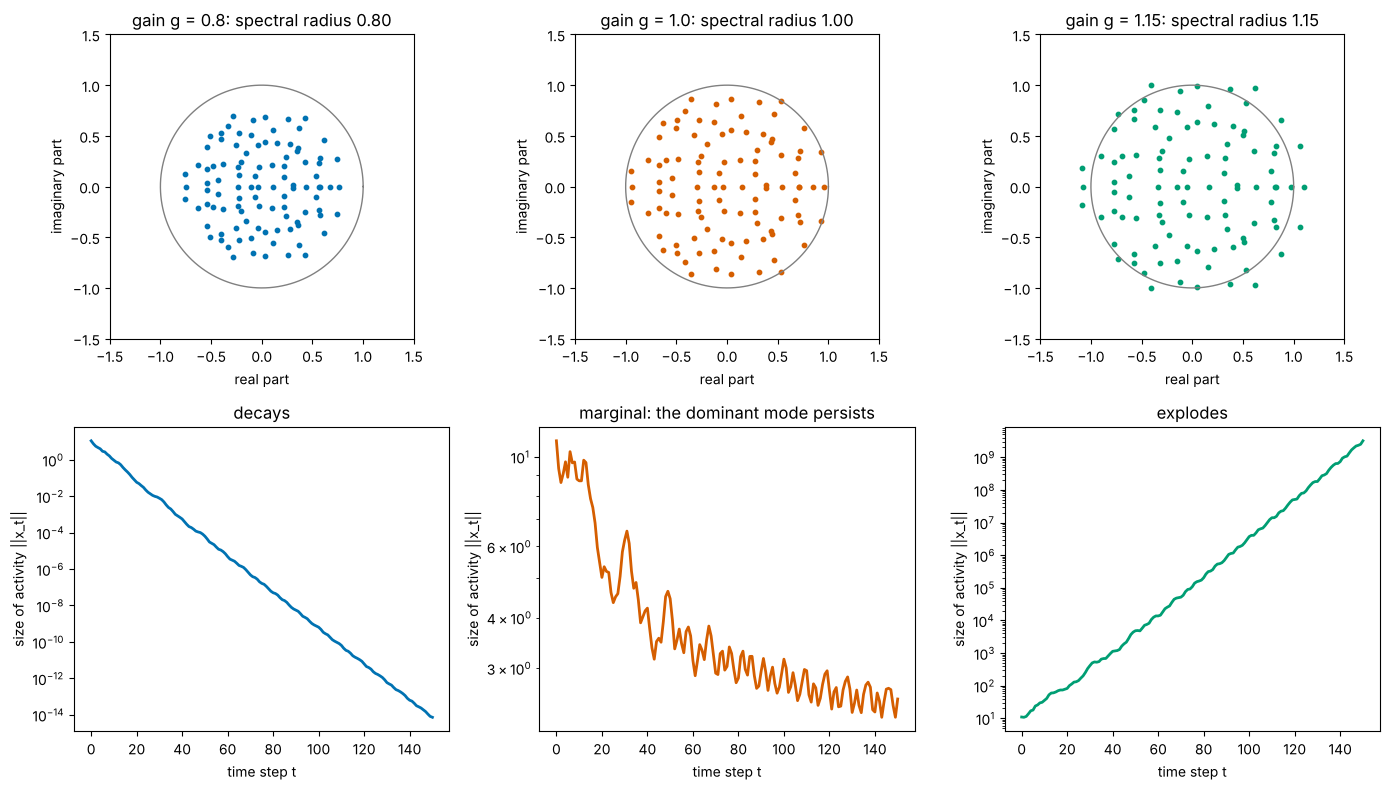

In [12]:
N_net = 100
W0 = RNG.normal(0, 1 / np.sqrt(N_net), size=(N_net, N_net))      # random weights: eigenvalues fill a disc of radius about 1
print(f'spectral radius of the raw random matrix: {np.abs(np.linalg.eigvals(W0)).max():.3f} (the circular law is only approximate for finite N)')
W0 = W0 / np.abs(np.linalg.eigvals(W0)).max()                    # rescale so the spectral radius is exactly 1, and g IS the spectral radius
x0_net = RNG.normal(size=N_net)
gains = [0.8, 1.0, 1.15]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, g in enumerate(gains):
    W = g * W0
    lam = np.linalg.eigvals(W)
    rho = np.abs(lam).max()
    ax = axes[0, col]
    ax.plot(unit_circle.real, unit_circle.imag, color='grey', lw=1)
    ax.scatter(lam.real, lam.imag, s=10, color=PALETTE[col])
    ax.set_aspect('equal'); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel('real part'); ax.set_ylabel('imaginary part')
    ax.set_title(f'gain g = {g}: spectral radius {rho:.2f}')
    traj = iterate(W, x0_net, 150)
    ax = axes[1, col]
    ax.semilogy(np.linalg.norm(traj, axis=1), color=PALETTE[col], lw=2)
    ax.set_xlabel('time step t'); ax.set_ylabel('size of activity ||x_t||')
    ax.set_title({0.8: 'decays', 1.0: 'marginal: the dominant mode persists', 1.15: 'explodes'}[g])
plt.tight_layout()
plt.show()

#### Interactive version: turn the gain up through the unit circle

In [13]:
# INTERACTIVE -- the gain g moves from 0.5 to 1.3; eigenvalues scale with g, and ||x_t|| follows the spectral radius
g_values = np.round(np.linspace(0.5, 1.3, 17), 2)
lam0 = np.linalg.eigvals(W0)
norms = {g: np.linalg.norm(iterate(g * W0, x0_net, 60), axis=1) for g in g_values}
fig_gain = make_subplots(rows=1, cols=2, subplot_titles=('Eigenvalues of g W0 and the unit circle', 'Size of activity ||x_t|| (log scale)'))
fig_gain.add_trace(go.Scatter(x=unit_circle.real, y=unit_circle.imag, mode='lines', line=dict(color='grey'), hoverinfo='skip', showlegend=False), row=1, col=1)
fig_gain.add_trace(go.Scatter(x=g_values[0] * lam0.real, y=g_values[0] * lam0.imag, mode='markers', marker=dict(color=PALETTE[0], size=5), showlegend=False), row=1, col=1)
fig_gain.add_trace(go.Scatter(x=np.arange(61), y=norms[g_values[0]], mode='lines', line=dict(color=PALETTE[1], width=3), showlegend=False), row=1, col=2)
fig_gain.frames = [go.Frame(name=str(k), traces=[1, 2], data=[go.Scatter(x=g * lam0.real, y=g * lam0.imag), go.Scatter(x=np.arange(61), y=norms[g])],
                            layout=go.Layout(title=f'gain g = {g:.2f}:  spectral radius {g * np.abs(lam0).max():.2f}'))
                   for k, g in enumerate(g_values)]
buttons, sliders = play_pause_and_slider([f'{g:.2f}' for g in g_values], prefix='g = ', duration=400)
fig_gain.update_xaxes(range=[-1.6, 1.6], title_text='real part', row=1, col=1)
fig_gain.update_yaxes(range=[-1.6, 1.6], scaleanchor='x', scaleratio=1, title_text='imaginary part', row=1, col=1)
fig_gain.update_yaxes(type='log', range=[-6, 6], title_text='||x_t||', row=1, col=2); fig_gain.update_xaxes(title_text='time step', row=1, col=2)
fig_gain.update_layout(title=fig_gain.frames[0].layout.title.text, template='plotly_white', width=1000, height=500, updatemenus=buttons, sliders=sliders)
fig_gain.show(config=PLOTLY_CONFIG)

In [14]:
dt_demo = 0.05   # seconds per time step
print(f"{'|lambda|':>9}{'tau (s)':>10}")
for r in [0.5, 0.8, 0.9, 0.95, 0.99, 0.999]:
    print(f"{r:9.3f}{-dt_demo / np.log(r):10.2f}")

 |lambda|   tau (s)
    0.500      0.07
    0.800      0.22
    0.900      0.47
    0.950      0.97
    0.990      4.97
    0.999     49.97


# **Part 6: Stability in Continuous Time — Rate Networks and Integrators**

Neurons change continuously. A standard **linear rate network** of $N$ neurons with time constant $\tau_n$ (tens of milliseconds) is

$$\tau_n\frac{d\mathbf{x}}{dt} = -\mathbf{x} + \mathbf{W}\mathbf{x} + \mathbf{u}(t),$$

where $-\mathbf{x}$ is each neuron's leak back to baseline, $\mathbf{W}\mathbf{x}$ is recurrent input, and $\mathbf{u}$ is external input. Without input this is $d\mathbf{x}/dt = \mathbf{A}\mathbf{x}$ with $\mathbf{A} = (\mathbf{W} - \mathbf{I})/\tau_n$.

In continuous time each eigen-direction evolves as $e^{\lambda t}$ instead of $\lambda^t$, so the solution is $\mathbf{x}(t) = \sum_i c_i e^{\lambda_i t}\mathbf{v}_i$, and:

- **stable** if every eigenvalue has **negative real part**, $\operatorname{Re}\lambda_i < 0$ (the left half-plane, not the unit circle);
- each mode decays with time constant $1/|\operatorname{Re}\lambda_i|$ and oscillates at frequency $|\operatorname{Im}\lambda_i|/2\pi$.

If $\mu$ is an eigenvalue of $\mathbf{W}$, then $(\mu - 1)/\tau_n$ is an eigenvalue of $\mathbf{A}$, with the same eigenvector. So the network is stable exactly when every eigenvalue of $\mathbf{W}$ has real part below 1. A mode with $\mu$ close to 1 has time constant $\tau_n/(1 - \mu)$, far longer than any single neuron's $\tau_n$: **recurrence can create slow timescales**.

### An integrator: exactly one eigenvalue of 1

If $\mathbf{W}$ has an eigenvalue $\mu = 1$ exactly, that mode neither decays nor grows: the network **holds** whatever was put into it. It integrates its input and remembers the total. The brainstem circuit that holds the eyes still after a saccade is thought to work this way (a "neural integrator", or line attractor).

eigenvalues of W: [1.  0.5]   eigenvalues of A = (W - I)/tau: [  0.+0.j -25.+0.j] per second


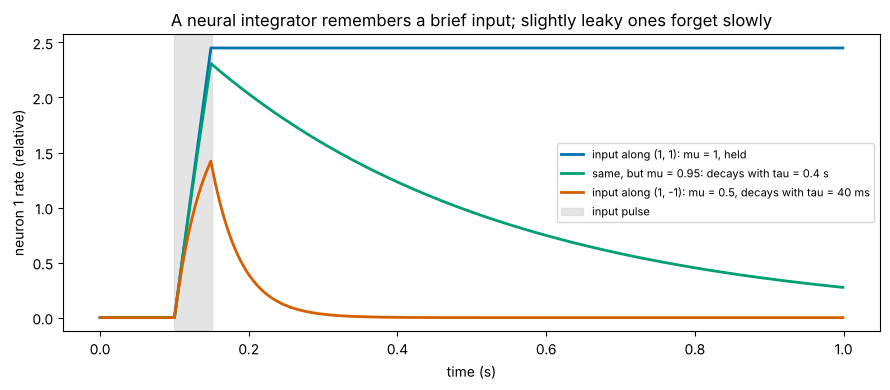

In [15]:
tau_n = 0.02                                                     # 20 ms neuronal time constant
W_int = np.array([[0.75, 0.25], [0.25, 0.75]])                   # eigenvalues 1 (along (1,1)) and 0.5 (along (1,-1))
mu = np.real_if_close(np.linalg.eigvals(W_int))
A_int = (W_int - np.eye(2)) / tau_n
print("eigenvalues of W:", mu, "  eigenvalues of A = (W - I)/tau:", np.round(np.linalg.eigvals(A_int), 2), "per second")

dt_sim = 0.001
t_sim = np.arange(0, 1.0, dt_sim)
pulse = np.where((t_sim > 0.1) & (t_sim < 0.15), 1.0, 0.0)
def simulate(W, input_vec, dt=dt_sim):
    x = np.zeros(2); xs = []
    for k in range(len(t_sim)):
        x = x + dt / tau_n * (-x + W @ x + input_vec * pulse[k])  # Euler step (Lesson 21 studies this properly)
        xs.append(x.copy())
    return np.array(xs)
x_along = simulate(W_int, np.array([1.0, 1.0]))      # pulse along the integrating direction
x_across = simulate(W_int, np.array([1.0, -1.0]))    # pulse along the decaying direction
W_leaky = np.array([[0.7, 0.25], [0.25, 0.7]])       # eigenvalue 0.95 instead of 1
x_leaky = simulate(W_leaky, np.array([1.0, 1.0]))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(t_sim, x_along[:, 0], color=PALETTE[0], lw=2, label='input along (1, 1): mu = 1, held')
ax.plot(t_sim, x_leaky[:, 0], color=PALETTE[2], lw=2, label='same, but mu = 0.95: decays with tau = 0.4 s')
ax.plot(t_sim, x_across[:, 0], color=PALETTE[1], lw=2, label='input along (1, -1): mu = 0.5, decays with tau = 40 ms')
ax.axvspan(0.1, 0.15, color='lightgrey', alpha=0.6, label='input pulse')
ax.set_xlabel('time (s)'); ax.set_ylabel('neuron 1 rate (relative)'); ax.set_title('A neural integrator remembers a brief input; slightly leaky ones forget slowly')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Note the numbers. The single neurons have a time constant of 20 ms, yet the network holds the input indefinitely along $(1, 1)$, and with $\mu = 0.95$ it forgets over $\tau_n/(1 - \mu) = 0.4$ s: twenty times longer than any neuron. Real integrators are slightly leaky, and how precisely biology tunes $\mu$ to 1 is a long-standing question.

**Discrete and continuous time are linked.** The exact one-step map of $d\mathbf{x}/dt = \mathbf{A}\mathbf{x}$ over a step $\Delta t$ has eigenvalues $e^{\lambda\Delta t}$: the left half-plane maps into the unit disc. The simple **Euler** step $\mathbf{x} \leftarrow \mathbf{x} + \Delta t\,\mathbf{A}\mathbf{x}$ multiplies by $\mathbf{I} + \Delta t\,\mathbf{A}$, with eigenvalues $1 + \Delta t\,\lambda$. Those leave the unit circle if $\Delta t$ is too large, making a stable system look unstable in simulation:

In [16]:
lam_fast = -1 / tau_n            # a single neuron's leak: lambda = -50 per second
for dt in [0.001, 0.01, 0.03, 0.05]:
    factor = 1 + dt * lam_fast
    print(f"Euler step dt = {dt * 1000:4.0f} ms: per-step factor 1 + dt*lambda = {factor:+.2f}  ->  {'stable' if abs(factor) < 1 else 'UNSTABLE simulation'}   (exact factor e^(lambda dt) = {np.exp(lam_fast * dt):.3f})")

Euler step dt =    1 ms: per-step factor 1 + dt*lambda = +0.95  ->  stable   (exact factor e^(lambda dt) = 0.951)
Euler step dt =   10 ms: per-step factor 1 + dt*lambda = +0.50  ->  stable   (exact factor e^(lambda dt) = 0.607)
Euler step dt =   30 ms: per-step factor 1 + dt*lambda = -0.50  ->  stable   (exact factor e^(lambda dt) = 0.223)
Euler step dt =   50 ms: per-step factor 1 + dt*lambda = -1.50  ->  UNSTABLE simulation   (exact factor e^(lambda dt) = 0.082)


# **Part 7: Mini-Lab — Fitting the Dynamics of Real Motor Cortex**

Does real population activity behave like $\mathbf{x}_{t+1} = \mathbf{A}\mathbf{x}_t$, and if so, what do the eigenvalues of $\mathbf{A}$ say? We use the motor-cortex recording from Lesson 5: 447 neurons in mouse primary motor cortex (MOp) while the mouse turned a wheel to report a visual choice ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x); Neuromatch Academy version; the original data are in the public domain, CC0). Each of the 342 trials lasts 2.5 s, regrouped into fifty 50 ms bins.

**Plan.**
1. Smooth each neuron's 50 ms rates a little (Gaussian, standard deviation one bin) **within each trial**, centre them, and keep the 20 neurons with the largest variance in the training trials (the first half).
2. Fit $\mathbf{A}$ ($20\times20$) by least squares on the training trials (Lesson 5): each bin's activity predicted from the previous bin's in the same trial.
3. Read its eigenvalues: spectral radius, timescales, rotation frequencies.
4. Check the fit on the held-out trials, and run two **controls** that ask how much of the result is real dynamics.

In [17]:
# Step 1: load, smooth within trials, centre, select

import os, urllib.request

MOP_FILE = 'steinmetz_s10_hench_mop.npz'
for candidate in [MOP_FILE, os.path.join('..', '..', 'data', MOP_FILE)]:   # a local copy, or the repository's data folder
    if os.path.exists(candidate):
        mop_path = candidate
        break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/' + MOP_FILE, MOP_FILE)
    mop_path = MOP_FILE
mop = np.load(mop_path)
BIN = 0.05                                                              # we use 50 ms bins (5 of the file's 10 ms bins)
n_trials, n_neurons, _ = mop['spikes'].shape
rates_3d = mop['spikes'].reshape(n_trials, n_neurons, 50, 5).sum(axis=3) / BIN   # (342, 447, 50): (trial, neuron, 50 ms bin), spikes/s
wheel_2d = mop['wheel'].reshape(n_trials, 50, 5).sum(axis=2) / BIN                # (342, 50): (trial, 50 ms bin), wheel velocity, encoder steps/s

dt = BIN                                                         # seconds per bin
train = np.arange(n_trials) < n_trials // 2                      # trials used for fitting
test = ~train

def smooth(R3, sigma_bins):
    # Gaussian smoothing along the last axis (time within a trial); sigma in bins. sigma = 0 returns the data unchanged.
    if sigma_bins == 0:
        return R3.copy()
    k = np.exp(-0.5 * (np.arange(-4 * sigma_bins, 4 * sigma_bins + 1) / sigma_bins)**2); k /= k.sum()
    return np.apply_along_axis(lambda x: np.convolve(x, k, mode='same'), -1, R3)

S_all = smooth(rates_3d, 1)                                      # (342, 447, 50)
mean_tr = S_all[train].mean(axis=(0, 2))                         # each neuron's TRAINING mean (Lesson 3)
var_tr = S_all[train].var(axis=(0, 2))
chosen = np.argsort(-var_tr)[:20]
Z3 = (S_all - mean_tr[None, :, None])[:, chosen, :].transpose(0, 2, 1)   # (342, 50, 20): (trial, time bin, neuron), spikes/s relative to mean
print("Z3 shape:", Z3.shape, " (trial, time bin, neuron); neurons chosen by training variance:", np.sort(chosen))

Z3 shape: (342, 50, 20)  (trial, time bin, neuron); neurons chosen by training variance: [ 29 135 139 163 251 257 265 267 270 320 323 328 429 431 432 433 434 436
 438 441]


In [18]:
# Step 2: fit A by least squares: Z[t+1] ~ A Z[t], using only pairs of bins inside the same trial.
def pairs(Z3, trials):
    # Returns (previous states, next states), each (n_pairs, n_neurons), from consecutive bins within the chosen trials.
    Zt = Z3[trials]
    return Zt[:, :-1].reshape(-1, Zt.shape[2]), Zt[:, 1:].reshape(-1, Zt.shape[2])

def fit_dynamics(Z3, trials):
    prev, nxt = pairs(Z3, trials)
    return np.linalg.lstsq(prev, nxt, rcond=None)[0].T          # with bins as rows, nxt ~ prev A^T

def one_step_r2(A, Z3, trials):
    prev, nxt = pairs(Z3, trials)
    pred = prev @ A.T
    return 1 - ((nxt - pred)**2).sum() / ((nxt - nxt.mean(axis=0))**2).sum()

A_mop = fit_dynamics(Z3, train)
print(f"A shape {A_mop.shape};  one-step R^2 on the held-out trials: {one_step_r2(A_mop, Z3, test):.3f}")
print(f"(baseline 'next bin = this bin', i.e. A = I: R^2 {one_step_r2(np.eye(20), Z3, test):.3f})")

A shape (20, 20);  one-step R^2 on the held-out trials: 0.903
(baseline 'next bin = this bin', i.e. A = I: R^2 0.888)


In [19]:
# Step 3: eigenvalues, spectral radius, timescales
lam_m, V_m = np.linalg.eig(A_mop)
order_m = np.argsort(-np.abs(lam_m)); lam_m, V_m = lam_m[order_m], V_m[:, order_m]
rho_m = np.abs(lam_m).max()
print(f"spectral radius: {rho_m:.3f}  -> {'stable' if rho_m < 1 else 'unstable'}")
print(f"complex pairs: {int((np.abs(lam_m.imag) > 1e-9).sum() // 2)} of {len(lam_m) // 2} possible")
print("\nslowest modes:")
shown = 0
for l in lam_m:
    if l.imag < -1e-9:
        continue                                                  # show each complex pair once
    print(f"  lambda = {l.real:.3f}{l.imag:+.3f}i   |lambda| {abs(l):.3f}   tau {-dt / np.log(abs(l)):.2f} s   frequency {abs(np.angle(l)) / (2 * np.pi * dt):.2f} Hz")
    shown += 1
    if shown == 4:
        break

spectral radius: 0.927  -> stable
complex pairs: 8 of 10 possible

slowest modes:
  lambda = 0.926+0.042i   |lambda| 0.927   tau 0.66 s   frequency 0.14 Hz
  lambda = 0.910+0.119i   |lambda| 0.918   tau 0.58 s   frequency 0.41 Hz
  lambda = 0.894+0.000i   |lambda| 0.894   tau 0.45 s   frequency 0.00 Hz
  lambda = 0.880+0.121i   |lambda| 0.888   tau 0.42 s   frequency 0.43 Hz


### Controls: is this the brain, or the method?

A fitted spectral radius close to 1 and a decay time of a fraction of a second sound like slow neural dynamics. But two things other than the brain can produce them.

1. **Smoothing.** Smoothing makes neighbouring bins similar *by construction*. Smoothed **noise**, which has no dynamics at all, would also give a fitted $\mathbf{A}$ with eigenvalues well above zero.
2. **Chance.** With 400 parameters, least squares will find some structure even in data with none.

So we refit the same model to (a) white noise smoothed with the same kernel, and (b) the real data with the bins of each training trial shuffled into random order, which keeps every neuron's rates but destroys temporal order.

In [20]:
noise3 = smooth(RNG.normal(size=Z3.transpose(0, 2, 1).shape), 1).transpose(0, 2, 1)   # (342, 50, 20) smoothed white noise
noise3 = noise3 - noise3[train].mean(axis=(0, 1))
A_noise = fit_dynamics(noise3, train)
Z3_shuf = Z3.copy()
for t in np.flatnonzero(train):
    Z3_shuf[t] = Z3[t, RNG.permutation(50)]                       # scramble the time order within each training trial
A_shuf = fit_dynamics(Z3_shuf, train)

def slowest_tau(A):
    l = np.abs(np.linalg.eigvals(A)).max()
    return -dt / np.log(l)
print(f"{'model fitted to':<38}{'spectral radius':>16}{'slowest tau (s)':>17}")
for name, A_ in [('real smoothed activity', A_mop), ('smoothed white noise (control a)', A_noise), ('time-shuffled activity (control b)', A_shuf)]:
    print(f"{name:<38}{np.abs(np.linalg.eigvals(A_)).max():>16.3f}{slowest_tau(A_):>17.2f}")

model fitted to                        spectral radius  slowest tau (s)
real smoothed activity                           0.927             0.66
smoothed white noise (control a)                 0.794             0.22
time-shuffled activity (control b)               0.505             0.07


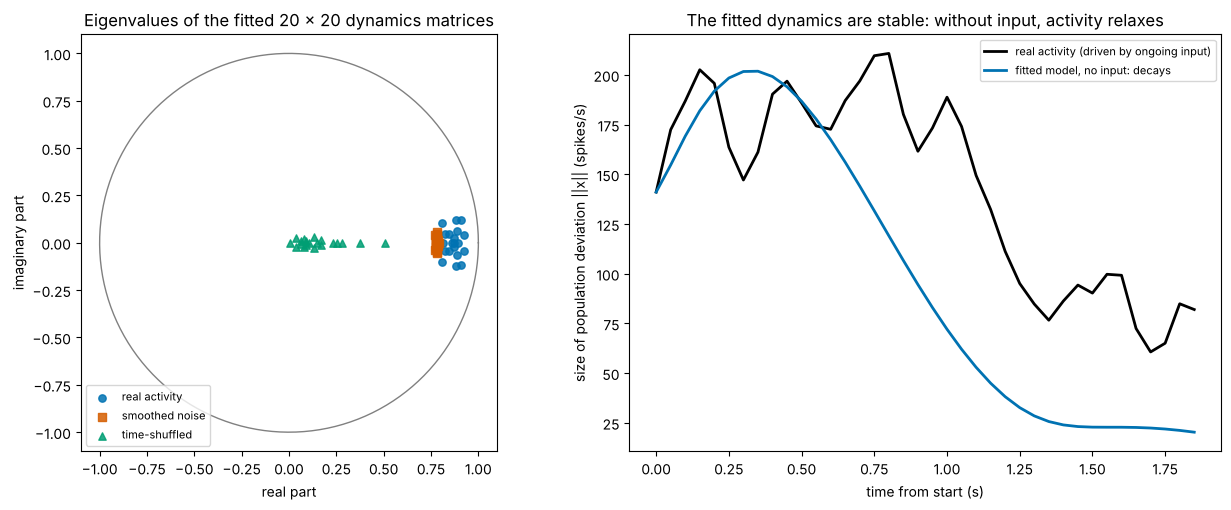

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
ax = axes[0]
ax.plot(unit_circle.real, unit_circle.imag, color='grey', lw=1)
for A_, name, colour, mk in [(A_mop, 'real activity', PALETTE[0], 'o'), (A_noise, 'smoothed noise', PALETTE[1], 's'), (A_shuf, 'time-shuffled', PALETTE[2], '^')]:
    l = np.linalg.eigvals(A_)
    ax.scatter(l.real, l.imag, s=28, color=colour, marker=mk, label=name, alpha=0.85)
ax.set_aspect('equal'); ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('real part'); ax.set_ylabel('imaginary part'); ax.set_title('Eigenvalues of the fitted 20 x 20 dynamics matrices')
ax.legend(fontsize=8, loc='lower left')

ax = axes[1]
# Free evolution: start from the state 0.6 s into a held-out trial (around the movement) and let the model run with no input
trial0 = np.flatnonzero(test & (mop['response'] != 0))[0]
start_bin = 12
free = iterate(A_mop, Z3[trial0, start_bin], 50 - start_bin - 1)
t_free = np.arange(50 - start_bin) * dt
ax.plot(t_free, np.linalg.norm(Z3[trial0, start_bin:], axis=1), color='black', lw=2, label='real activity (driven by ongoing input)')
ax.plot(t_free, np.linalg.norm(free, axis=1), color=PALETTE[0], lw=2, label='fitted model, no input: decays')
ax.set_xlabel('time from start (s)'); ax.set_ylabel('size of population deviation ||x|| (spikes/s)')
ax.set_title('The fitted dynamics are stable: without input, activity relaxes')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

#### Interactive version: hover over the eigenvalues

In [22]:
fig_ev = go.Figure()
fig_ev.add_trace(go.Scatter(x=unit_circle.real, y=unit_circle.imag, mode='lines', line=dict(color='grey'), hoverinfo='skip', name='unit circle'))
for A_, name, colour, sym in [(A_mop, 'real activity', PALETTE[0], 'circle'), (A_noise, 'smoothed noise', PALETTE[1], 'square'), (A_shuf, 'time-shuffled', PALETTE[2], 'triangle-up')]:
    l = np.linalg.eigvals(A_)
    tau_l = -dt / np.log(np.abs(l)); f_l = np.abs(np.angle(l)) / (2 * np.pi * dt)
    fig_ev.add_trace(go.Scatter(x=l.real, y=l.imag, mode='markers', name=name, marker=dict(color=colour, size=9, symbol=sym),
                                customdata=np.stack([np.abs(l), tau_l, f_l], axis=1),
                                hovertemplate='|lambda| %{customdata[0]:.3f}<br>tau %{customdata[1]:.2f} s<br>frequency %{customdata[2]:.2f} Hz<extra>' + name + '</extra>'))
fig_ev.update_layout(title='Fitted eigenvalues (hover for timescale and frequency)', template='plotly_white', width=650, height=620,
                     xaxis=dict(range=[-1.1, 1.1], title='real part'), yaxis=dict(range=[-1.1, 1.1], title='imaginary part', scaleanchor='x', scaleratio=1))
fig_ev.show(config=PLOTLY_CONFIG)

**Interpretation.** A $20\times20$ linear dynamics matrix predicts the next 50 ms of held-out activity well (one-step $R^2$ about 0.90), and its spectral radius, 0.93, is below 1. Left to itself, the fitted circuit relaxes back to baseline: it is stable. (In the right panel the model's activity first *grows* for about 0.3 s before it decays. Eigenvalues govern the long run; a stable matrix whose eigenvectors are far from orthogonal can still amplify some starting states for a while.) Most eigenvalues come in complex pairs (8 of 10 possible), so the fitted dynamics contain rotating modes, though slow ones (below 0.5 Hz). The slowest mode decays with a time constant of about 0.66 s.

The controls change how that number should be read. Time-shuffled activity gives a spectral radius of only about 0.5 (time constant 0.07 s), so the temporal structure is real. But smoothed white noise, with no dynamics at all, already gives a slowest timescale of about 0.22 s, purely from the smoothing. The real activity is clearly slower than that (about three times), but part of any timescale measured this way comes from the preprocessing. Exercise 7 asks how much.

There is also a caution in the prediction score. Predicting "the next bin equals this bin" ($\mathbf{A} = \mathbf{I}$) already scores almost as high (0.89), because smoothed activity changes slowly. The fitted $\mathbf{A}$ is still better, but a high one-step $R^2$ alone proves little.

**Limitations.** The real circuit is driven by inputs (the visual stimulus, other brain areas, and the movement itself); a model with no input attributes some of that drive to $\mathbf{A}$. Twenty neurons out of 447 are a tiny, biased sample of the circuit. The dynamics are certainly not linear, and they change within a trial (before, during and after the movement). Eigenvalues of a fitted matrix carry statistical uncertainty that we have not measured; comparing halves of the session, or resampling trials, would. Population-dynamics studies of motor cortex address these issues with careful models of inputs and many more neurons. Their tool is still, at heart, the eigenvalues of a fitted matrix.

# **Part 8: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Spectral radius $\rho(\mathbf{W})$ | stability of recurrent circuits; runaway excitation (seizure-like activity) when $\rho > 1$ | exploding/vanishing gradients in recurrent networks; "edge of chaos" initialisation with $\rho \approx 1$ |
| Eigenvalue near 1 | neural integrators, working memory, line attractors | long-memory units; reservoir computing tuned near $\rho = 1$ |
| Complex eigenvalues | E–I oscillations; rotational dynamics in motor cortex | oscillatory modes in linear RNNs and state-space models |
| Mode decomposition | separating fast and slow timescales in population activity | principal components (Lesson 7); spectral methods |
| Power iteration | — | PageRank; dominant eigenvectors of huge sparse matrices |
| Symmetric matrices | covariance of neural populations, symmetric connectivity | covariance, kernels, Hessians (Lesson 14) |
| Continuous-time stability | linearised neuron and network models (Lessons 21–23 use the Jacobian) | neural ODEs, stable state-space models |

The circular law of Part 5 underlies a classic result in theoretical neuroscience: random recurrent networks switch from quiescent to chaotic activity when the gain crosses 1 (Sompolinsky, Crisanti and Sommers, 1988). Machine-learning practice borrowed the same idea to initialise recurrent networks near that edge.

# **Part 9: Summary and Lesson 7 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Eigenvector, eigenvalue | $\mathbf{A}\mathbf{v} = \lambda\mathbf{v}$, `np.linalg.eig` | directions only stretched, by $\lambda$ |
| Characteristic equation | $\det(\mathbf{A} - \lambda\mathbf{I}) = 0$; $2\times2$: $\lambda^2 - \operatorname{tr}\lambda + \det = 0$ | eigenvalues sum to the trace, multiply to the determinant |
| Types | discriminant $\operatorname{tr}^2 - 4\det$ | $>0$ real, $=0$ repeated, $<0$ complex (rotation) |
| Complex eigenvalue | $\lambda = r e^{i\theta}$ | rotate by $\theta$, scale by $r$ each step |
| Diagonalisation | $\mathbf{A} = \mathbf{V}\boldsymbol\Lambda\mathbf{V}^{-1}$, $\mathbf{A}^t = \mathbf{V}\boldsymbol\Lambda^t\mathbf{V}^{-1}$ | not every matrix (defective ones) |
| Modes | $\mathbf{x}_t = \sum_i c_i\lambda_i^t\mathbf{v}_i$ | the dominant mode wins; power iteration finds it |
| Symmetric matrices | `np.linalg.eigh` | real eigenvalues, orthogonal eigenvectors |
| Discrete stability | $\rho = \max_i|\lambda_i| < 1$ | timescale $\tau = -\Delta t/\ln|\lambda|$, frequency $|\arg\lambda|/2\pi\Delta t$ |
| Continuous stability | $\operatorname{Re}\lambda_i < 0$ | rate network stable iff $\operatorname{Re}\mu_i(\mathbf{W}) < 1$; timescale $\tau_n/(1 - \mu)$ |
| Fitted dynamics | least squares, then eigenvalues | always compare with controls (noise, shuffling) |

**Lesson 7** applies eigenvectors to the most common symmetric matrix in data analysis, the **covariance matrix**. Its eigenvectors are the directions along which a population of neurons varies most: the **principal components**. Its eigenvalues measure how much variance each direction carries. That is PCA.